In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# MyTorch imports
from mytorch.tensor import Tensor
from mytorch.model import Model
from mytorch.layer.linear import Linear
from mytorch.activation import tanh, sigmoid
from mytorch.activation.softmax import softmax  # not used here, but imported if you want
from mytorch.loss.mse import MeanSquaredError
from mytorch.optimizer import Adam, SGD, Momentum, RMSprop


In [2]:
# ------------------------------------------------------
# 1) LOAD WDBC.DATA (WISCONSIN DIAGNOSTIC BREAST CANCER)
# ------------------------------------------------------
# The file has 32 columns in total:
#  - Column 0: ID number
#  - Column 1: Diagnosis ('M' or 'B')
#  - Columns 2..31: 30 real-valued features
column_names = ["ID", "Diagnosis"] + [f"Feature_{i}" for i in range(1,31)]
df = pd.read_csv("wdbc.data", header=None, names=column_names, usecols=range(32))

# Convert 'M' -> 1, 'B' -> 0
df["Diagnosis"] = df["Diagnosis"].map({"M": 1, "B": 0})

# Extract features (X) and labels (y)
X = df.iloc[:, 2:].values  # columns 2..31 => 30 features
y = df["Diagnosis"].values # single binary label

# Shuffle data (optional)
np.random.seed(25)
indices = np.random.permutation(len(X))
X = X[indices]
y = y[indices]

In [3]:
# -----------------------------------
# 2) SPLIT INTO TRAIN & TEST (80/20)
# -----------------------------------
split_idx = int(len(X)*0.8)
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

# ---------------------------------------------
# 3) CONVERT NUMPY ARRAYS TO MYTORCH TENSORS
# ---------------------------------------------
X_train_tensor = Tensor(X_train, requires_grad=True)
y_train_tensor = Tensor(y_train.reshape(-1,1), requires_grad=False)  # shape (N,1)
X_test_tensor = Tensor(X_test, requires_grad=False)
y_test_tensor = Tensor(y_test.reshape(-1,1), requires_grad=False)

In [4]:

# -----------------------------------------------------------------------
# 4) DEFINE A MODEL (SIMILAR STRUCTURE, BUT FOR BREAST CANCER, BINARY)
# -----------------------------------------------------------------------
class BreastCancerModel(Model):
    def __init__(self):
        super().__init__()
        self.layer1 = Linear(30, 16)  # 30 input features -> 16 hidden units
        self.layer2 = Linear(16, 1)   # single output for binary classification
    
    def forward(self, x):
        # We can use tanh (like the code used for Iris),
        # then a sigmoid for the final output => binary classification
        x = self.layer1.forward(x)
        x = tanh(x)
        x = self.layer2.forward(x)
        x = sigmoid(x)
        return x

model = BreastCancerModel()

# ------------------------------------------------
# 5) LOSS FUNCTION (MSE) & OPTIMIZER (ADAM, ETC.)
# ------------------------------------------------
criterion = MeanSquaredError
optimizer = Adam(model.parameters(), lr=0.002)  
# or try SGD, Momentum, RMSprop, etc.


In [ ]:

# ------------------------------------------------
# 6) TRAINING LOOP (FULL-BATCH, LIKE YOUR IRIS CODE)
# ------------------------------------------------
epochs = 500
training_accuracies = []
testing_accuracies = []

for epoch in range(epochs):
    # Forward pass on *all* training data
    train_features = Tensor(X_train, requires_grad=True)  # refresh so we can do .backward()
    train_labels   = Tensor(y_train.reshape(-1,1), requires_grad=False)
    
    predictions = model.forward(train_features)
    loss = criterion(predictions, train_labels)
    
    # Backward pass & optimizer update
    loss.backward()
    optimizer.step()
    optimizer.zero_grad()
    
 
    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {loss.data:.4f}")

    # Train accuracy calculation
    pred_train_labels = (predictions.data >= 0.5).astype(int).ravel()
    train_accuracy = (pred_train_labels == y_train).mean() * 100
    training_accuracies.append(train_accuracy)
    

    # Test accuracy calculation
    test_features = Tensor(X_test)
    test_predictions = model.forward(test_features)
    pred_test_labels = (test_predictions.data >= 0.5).astype(int).ravel()
    test_accuracy = (pred_test_labels == y_test).mean() * 100
    testing_accuracies.append(test_accuracy)


Epoch [10/500], Loss: 0.1884
Epoch [20/500], Loss: 0.1747
Epoch [30/500], Loss: 0.1629
Epoch [40/500], Loss: 0.1508
Epoch [50/500], Loss: 0.1386
Epoch [60/500], Loss: 0.1281
Epoch [70/500], Loss: 0.1184
Epoch [80/500], Loss: 0.1099
Epoch [90/500], Loss: 0.1031
Epoch [100/500], Loss: 0.0974
Epoch [110/500], Loss: 0.0922
Epoch [120/500], Loss: 0.0870
Epoch [130/500], Loss: 0.0818
Epoch [140/500], Loss: 0.0778
Epoch [150/500], Loss: 0.0743
Epoch [160/500], Loss: 0.0713
Epoch [170/500], Loss: 0.0688
Epoch [180/500], Loss: 0.0665
Epoch [190/500], Loss: 0.0644
Epoch [200/500], Loss: 0.0625
Epoch [210/500], Loss: 0.0609
Epoch [220/500], Loss: 0.0593
Epoch [230/500], Loss: 0.0580
Epoch [240/500], Loss: 0.0568
Epoch [250/500], Loss: 0.0556
Epoch [260/500], Loss: 0.0545
Epoch [270/500], Loss: 0.0536
Epoch [280/500], Loss: 0.0525
Epoch [290/500], Loss: 0.0515
Epoch [300/500], Loss: 0.0505
Epoch [310/500], Loss: 0.0494
Epoch [320/500], Loss: 0.0482
Epoch [330/500], Loss: 0.0519
Epoch [340/500], Lo


Final Test Accuracy: 94.74%


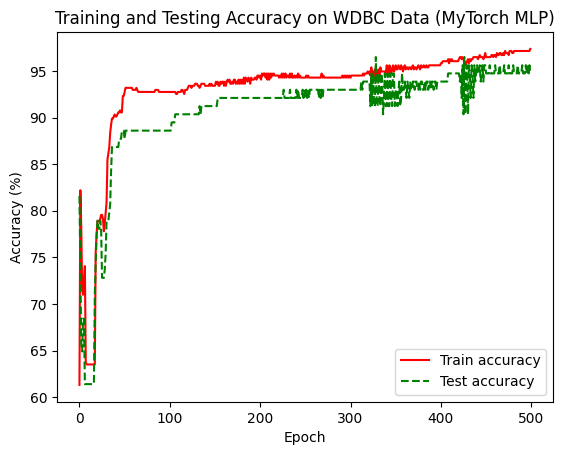

In [6]:
# ---------------------------------------------------------
# 7) FINAL EVALUATION
# ---------------------------------------------------------
correct = 0
total = len(y_test)

test_inputs = Tensor(X_test)
test_outputs = model.forward(test_inputs)
test_pred_labels = (test_outputs.data >= 0.5).astype(int).ravel()

correct = (test_pred_labels == y_test).sum()
accuracy = (correct / total) * 100
print(f"\nFinal Test Accuracy: {accuracy:.2f}%")

# ---------------------------------------------------------
# 8) PLOT THE TRAIN/TEST ACCURACY OVER EPOCHS
# ---------------------------------------------------------
plt.figure()
plt.plot(training_accuracies, label="Train accuracy", color='red')
plt.plot(testing_accuracies, label="Test accuracy", color='green', linestyle='dashed')
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.title("Training and Testing Accuracy on WDBC Data (MyTorch MLP)")
plt.show()